**NOMOR 3**

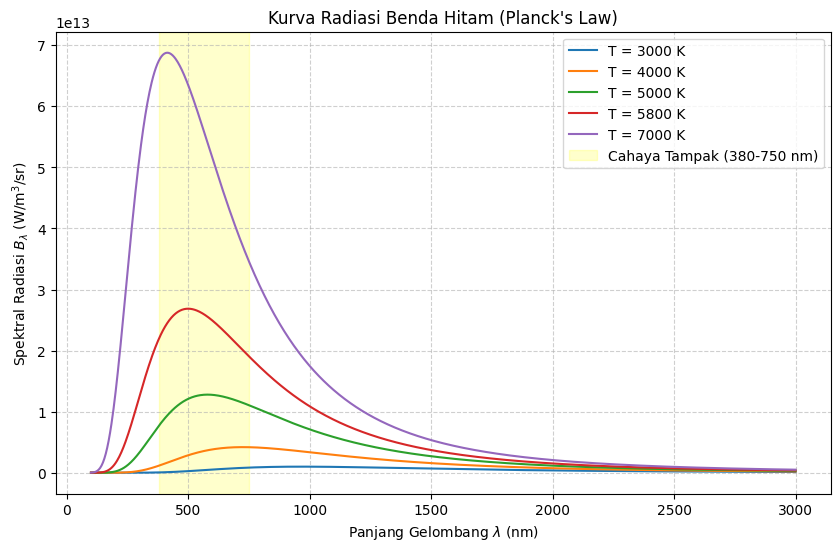

Verifikasi Hukum Pergeseran Wien (b_teoritis = 2.898e-3 m·K):
T (K)    | lambda_max (nm) | b_calc (m·K)    | Error (%) 
-------------------------------------------------------
3000     | 965.07          | 2.89520e-03     | 0.10      %
4000     | 724.12          | 2.89650e-03     | 0.05      %
5000     | 578.98          | 2.89489e-03     | 0.11      %
5800     | 500.60          | 2.90348e-03     | 0.19      %
7000     | 413.51          | 2.89459e-03     | 0.12      %

Analisis untuk Matahari (T = 5800 K):
Puncak radiasi Matahari berada pada panjang gelombang sekitar 500.6 nm.
Panjang gelombang tersebut berada tepat di wilayah spektrum cahaya tampak khususnya daerah hijau-kuning. Hal ini menjelaskan mengapa mata manusia berevolusi menjadi sangat sensitif terhadap cahaya hijau-kuning karena energi radiasi dari Matahari paling melimpah dan maksimum pada rentang tersebut.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

h = 6.626e-34   # J·s
c = 3.00e8      # m/s
k_B = 1.381e-23 # J/K

def planck(lam, T):
    a = 2.0 * h * c**2
    b = (h * c) / (lam * k_B * T)
    return a / (lam**5 * np.expm1(b))

lam_nm = np.linspace(100, 3000, 1000)
lam_m = lam_nm * 1e-9
temperatures = [3000, 4000, 5000, 5800, 7000]

plt.figure(figsize=(10, 6))

b_theoretical = 2.898e-3 # m·K
results = []

for T in temperatures:
    B = planck(lam_m, T)
    plt.plot(lam_nm, B, label=f'T = {T} K')

    idx_max = np.argmax(B)
    lam_max_m = lam_m[idx_max]
    b_calc = lam_max_m * T
    error = abs(b_calc - b_theoretical) / b_theoretical * 100
    results.append((T, lam_max_m * 1e9, b_calc, error))

plt.axvspan(380, 750, color='yellow', alpha=0.2, label='Cahaya Tampak (380-750 nm)')

plt.title("Kurva Radiasi Benda Hitam (Planck's Law)")
plt.xlabel("Panjang Gelombang $\\lambda$ (nm)")
plt.ylabel("Spektral Radiasi $B_\\lambda$ (W/m$^3$/sr)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("Verifikasi Hukum Pergeseran Wien (b_teoritis = 2.898e-3 m·K):")
print(f"{'T (K)':<8} | {'lambda_max (nm)':<15} | {'b_calc (m·K)':<15} | {'Error (%)':<10}")
print("-" * 55)
for T, l_max, b_c, err in results:
    print(f"{T:<8} | {l_max:<15.2f} | {b_c:<15.5e} | {err:<10.2f}%")

print("\nAnalisis untuk Matahari (T = 5800 K):")
idx_sun = temperatures.index(5800)
lam_sun_max = results[idx_sun][1]
print(f"Puncak radiasi Matahari berada pada panjang gelombang sekitar {lam_sun_max:.1f} nm.")
print("Panjang gelombang tersebut berada tepat di wilayah spektrum cahaya tampak khususnya daerah hijau-kuning. Hal ini menjelaskan mengapa mata manusia berevolusi menjadi sangat sensitif terhadap cahaya hijau-kuning karena energi radiasi dari Matahari paling melimpah dan maksimum pada rentang tersebut.")

**NOMOR 4**

Analisis Probabilitas Teoritik:
P(State 1) = |1/2|^2 = 0.2500
P(State 2) = |1/√2|^2 = 0.5000
P(State 3) = |i/2|^2 = 0.2500
Total Probabilitas = 1.0000 (Keadaan ternormalisasi sempurna karena bernilai 1)



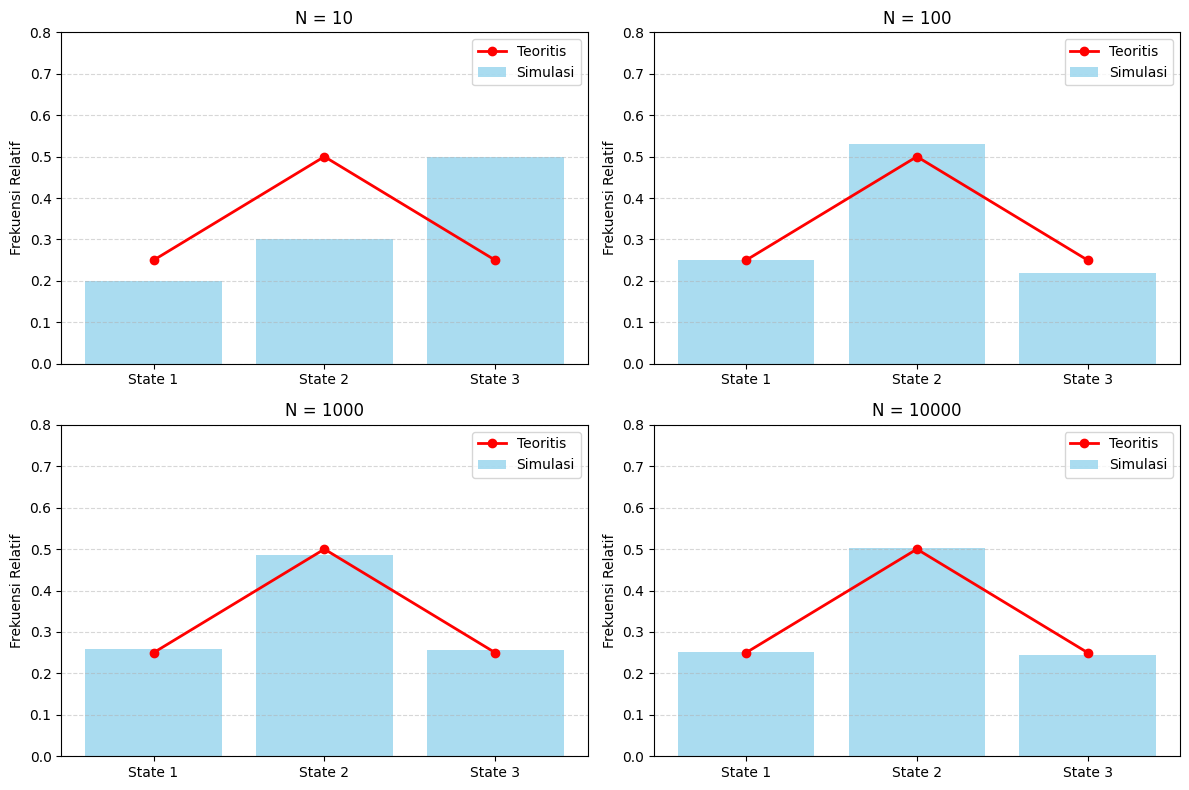

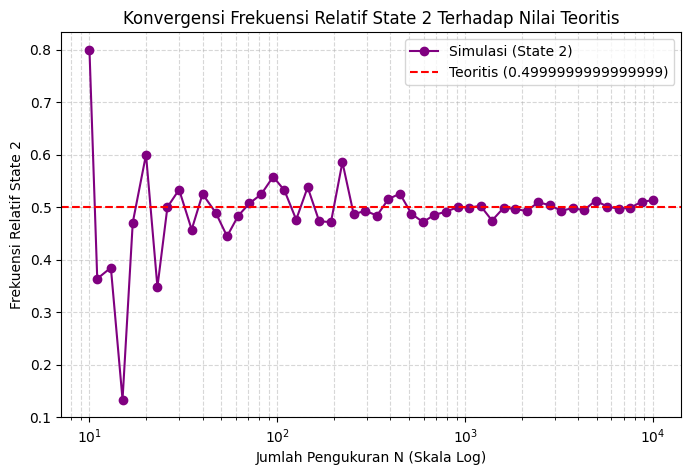

Jika c3 diubah menjadi -1/2, probabilitasnya menjadi | -1/2 |^2 = 0.2500.
Kesimpulannya yakni besar probabilitas hasil pengukuran tidak berubah karena probabilitas ditentukan oleh kuadrat nilai mutlak (|c_i|^2) yang menghilangkan komponen fasa kompleks.


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Koefisien superposisi
# psi = c1*psi1 + c2*psi2 + c3*psi3
c1 = 0.5
c2 = 1.0 / np.sqrt(2)
c3 = 0.5j # i / 2

#Analisis normalisasi dan probabilitas teoritis
prob1 = abs(c1)**2
prob2 = abs(c2)**2
prob3 = abs(c3)**2
total_prob = prob1 + prob2 + prob3

print("Analisis Probabilitas Teoritik:")
print(f"P(State 1) = |1/2|^2 = {prob1:.4f}")
print(f"P(State 2) = |1/√2|^2 = {prob2:.4f}")
print(f"P(State 3) = |i/2|^2 = {prob3:.4f}")
print(f"Total Probabilitas = {total_prob:.4f} (Keadaan ternormalisasi sempurna karena bernilai 1)\n")

states = ['State 1', 'State 2', 'State 3']
probabilities = [prob1, prob2, prob3]

N_values = [10, 100, 1000, 10000]
rng = np.random.default_rng(seed=42)

plt.figure(figsize=(12, 8))
for i, N in enumerate(N_values, 1):
    measurements = rng.choice(states, size=N, p=probabilities)
    counts = {s: np.sum(measurements == s) / N for s in states}

    plt.subplot(2, 2, i)
    plt.bar(states, [counts[s] for s in states], alpha=0.7, label='Simulasi', color='skyblue')
    plt.plot(states, probabilities, 'ro-', label='Teoritis', linewidth=2)
    plt.title(f'N = {N}')
    plt.ylabel('Frekuensi Relatif')
    plt.ylim(0, 0.8)
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
N_range = np.logspace(1, 4, 50, dtype=int)
freq_state2 = []

for N in N_range:
    measurements = rng.choice(states, size=N, p=probabilities)
    freq = np.sum(measurements == 'State 2') / N
    freq_state2.append(freq)

plt.semilogx(N_range, freq_state2, marker='o', linestyle='-', color='purple', label='Simulasi (State 2)')
plt.axhline(prob2, color='red', linestyle='--', label=f'Teoritis ({prob2})')
plt.title('Konvergensi Frekuensi Relatif State 2 Terhadap Nilai Teoritis')
plt.xlabel('Jumlah Pengukuran N (Skala Log)')
plt.ylabel('Frekuensi Relatif State 2')
plt.legend()
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.show()
c3_new = -0.5
new_prob3 = abs(c3_new)**2
print(f"Jika c3 diubah menjadi -1/2, probabilitasnya menjadi | -1/2 |^2 = {new_prob3:.4f}.")
print("Kesimpulannya yakni besar probabilitas hasil pengukuran tidak berubah karena probabilitas ditentukan oleh kuadrat nilai mutlak (|c_i|^2) yang menghilangkan komponen fasa kompleks.")